In [4]:
%load_ext autoreload
%autoreload 2

import copy
import random
import re
from collections import Counter
from pathlib import Path
import json
from time import time, sleep
 
import mne
import numpy as np
import pandas as pd
import torch
#import torch.nn as nn
#from numpy.lib.stride_tricks import sliding_window_view
#from torch.utils.data import DataLoader, Dataset

#import matplotlib.pyplot as plt
#from torchview import draw_graph

import seeg_fingerprint_hw3 as sf

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
torch.cuda.is_available()

True

In [ ]:
base = Path('/dashboard/example_data/sub-HUP060')
stem = 'sub-HUP060_ses-presurgery_task-interictal_acq-seeg_run-{:02d}'

edfs = [base / (stem.format(r) + '_ieeg.edf') for r in (1, 2)]
tsv  = base / (stem.format(2) + '_channels.tsv')

channels = sf.good_channels(tsv, edfs)
print(len(channels), 'contacts')
FS = 256
WIN_SEC = 1.0
NORM = 'global'
config = dict(norm=NORM, fs=FS, win_sec=WIN_SEC, avg_ref=True)
channels = sf.good_channels(tsv, edfs)
loaders, win = sf.build_loaders(edfs[0], edfs[1], channels, fs=FS, win_sec=WIN_SEC, norm=NORM)

model = sf.build_simple_cnn(win, len(channels))
model_graph = draw_graph(model, input_size=(1, 1, 256), device='cpu', save_graph=True, graph_name='hw2_cnn')

36 contacts


In [ ]:
import time
from math import ceil
from itertools import islice
from pathlib import Path

SUB = 'sub-HUP060'
FS, WIN_SEC, NORM = 256, 1.0, 'global'
BATCH, NUM_WORKERS, N_REPEATS = 128, 4, 10

base = Path(f'/dashboard/example_data/{SUB}')
stem = f'{SUB}_ses-presurgery_task-interictal_acq-seeg_run-{{:02d}}'
edfs = [base / (stem.format(r) + '_ieeg.edf') for r in (1, 2)]
tsv = base / (stem.format(2) + '_channels.tsv')

encoder = sf.ImageEncoder(size=64, mtf_bins=8, lag_samples=(2, 8, 32),
                          grid_bins=16, grid_range=(-4.0, 4.0), gaf_scale=None)
channels = sf.good_channels(tsv, edfs)
loaders, win = sf.build_loaders(edfs[0], edfs[1], channels, fs=FS, win_sec=WIN_SEC, norm=NORM,
                                batch_size=BATCH, encoder=encoder, num_workers=NUM_WORKERS)

# one batch of raw (normalized) windows
X = loaders['train'].dataset.tensors[0][:BATCH].numpy().astype(np.float64)
print(f'{len(channels)} contacts, batch of {X.shape[0]} windows x {X.shape[1]} samples')

def bench(fn, n=N_REPEATS):
    fn()                                           # warm-up (pyts uses numba; first call compiles)
    times = []
    for _ in range(n):
        t = time.perf_counter(); fn(); times.append(time.perf_counter() - t)
    return np.median(times) * 1000                 # ms

parts = {
    'GAF':       bench(lambda: encoder.gaf.fit_transform(X)),
    'MTF':       bench(lambda: encoder.mtf.fit_transform(X)),
    'lag grids': bench(lambda: sf.lag_grids(X, encoder.lag_samples, encoder.grid_bins, *encoder.grid_range)),
    'full encode': bench(lambda: encoder.encode(X)),
}
for k, v in parts.items():
    print(f'{k:12s} {v:7.1f} ms per batch')

# estimated epoch time from the encoder alone (single process vs. with workers)
n_train = len(loaders['train'].dataset)
n_batches = ceil(n_train / BATCH)
per_batch = parts['full encode'] / 1000
print(f'\ntrain windows: {n_train}, batches/epoch: {n_batches}')
print(f'encoding only, 1 process:  {n_batches * per_batch / 60:.1f} min/epoch')
print(f'encoding only, {NUM_WORKERS} workers:  {n_batches * per_batch / NUM_WORKERS / 60:.1f} min/epoch (ideal scaling)')

# measured loader throughput with real workers (first batch absorbs worker startup)
it = iter(loaders['train'])
next(it)
n_meas = min(20, n_batches - 1)
t0 = time.perf_counter()
for _ in islice(it, n_meas):
    pass
dt = (time.perf_counter() - t0) / n_meas
print(f'measured loader: {dt * 1000:.1f} ms/batch -> {n_batches * dt / 60:.1f} min/epoch (data loading only)')
del it

36 contacts, batch of 128 windows x 256 samples
GAF              3.6 ms per batch
MTF             16.3 ms per batch
lag grids        0.7 ms per batch
full encode     23.1 ms per batch

train windows: 63468, batches/epoch: 496
encoding only, 1 process:  0.2 min/epoch
encoding only, 4 workers:  0.0 min/epoch (ideal scaling)
measured loader: 13.5 ms/batch -> 0.1 min/epoch (data loading only)


In [ ]:
from pathlib import Path

import numpy as np

SUB = 'sub-HUP060'
FS, WIN_SEC, NORM = 256, 1.0, 'global'
RANGES = [3, 4, 5, 6, 8]               # symmetric ranges to compare, in normalized units

base = Path(f'/dashboard/example_data/{SUB}')
stem = f'{SUB}_ses-presurgery_task-interictal_acq-seeg_run-{{:02d}}'
edfs = [base / (stem.format(r) + '_ieeg.edf') for r in (1, 2)]
tsv = base / (stem.format(2) + '_channels.tsv')

encoder = sf.ImageEncoder(size=64, mtf_bins=8, lag_samples=(2, 8, 32),
                          grid_bins=16, grid_range=(-4.0, 4.0), gaf_scale=None)
channels = sf.good_channels(tsv, edfs)
loaders, win = sf.build_loaders(edfs[0], edfs[1], channels, fs=FS, win_sec=WIN_SEC, norm=NORM,
                                encoder=encoder, num_workers=0)    # no workers needed here

def per_contact_clipped(X, y, lo, hi, n_contacts):
    """Fraction of samples outside [lo, hi], per contact."""
    clipped = ((X < lo) | (X > hi)).mean(axis=1)                    # per window
    return np.bincount(y, weights=clipped, minlength=n_contacts) / np.bincount(y, minlength=n_contacts)

n_c = len(channels)
X, y = (t.numpy() for t in loaders['train'].dataset.tensors)         # already normalized
print(f'{SUB}: {n_c} contacts, {len(X)} train windows, norm={NORM}')

# 1) how the choice of range changes clipping (train split)
print('\nrange      mean    95th pct   worst   contacts with >5% clipped')
for r in RANGES:
    f = per_contact_clipped(X, y, -r, r, n_c)
    print(f'±{r:<4}   {f.mean():7.4f}  {np.percentile(f, 95):8.4f}  {f.max():6.4f}   {(f > 0.05).sum():>3d} / {n_c}')

# 2) worst contacts at the range currently set on the encoder
lo, hi = encoder.grid_range
f = per_contact_clipped(X, y, lo, hi, n_c)
sd = np.array([X[y == c].std() for c in range(n_c)])
print(f'\nWorst contacts at current range ({lo}, {hi}):')
for c in np.argsort(f)[::-1][:5]:
    print(f'  {channels[c]:12s} clipped {f[c]:.3f}   std in normalized units {sd[c]:.2f}')
print(f'Spread of per-contact std: min {sd.min():.2f}, median {np.median(sd):.2f}, max {sd.max():.2f}')

# 3) same check on the other splits at the current range (train-based normalization applied)
print('\nOther splits at current range:')
for split in ('val', 'test', 'run2'):
    Xs, ys = (t.numpy() for t in loaders[split].dataset.tensors)
    fs_ = per_contact_clipped(Xs, ys, lo, hi, n_c)
    print(f'  {split:5s} mean {fs_.mean():.4f}   worst {fs_.max():.4f}')

sub-HUP060: 36 contacts, 63468 train windows, norm=global

range      mean    95th pct   worst   contacts with >5% clipped
±3       0.0154    0.0595  0.1305     2 / 36
±4       0.0041    0.0168  0.0504     1 / 36
±5       0.0012    0.0048  0.0189     0 / 36
±6       0.0004    0.0017  0.0067     0 / 36
±8       0.0001    0.0004  0.0018     0 / 36

Worst contacts at current range (-4.0, 4.0):
  RAFd3        clipped 0.050   std in normalized units 2.05
  RPFc3        clipped 0.038   std in normalized units 1.92
  RH3          clipped 0.010   std in normalized units 1.48
  RAFb4        clipped 0.008   std in normalized units 1.38
  RH1          clipped 0.007   std in normalized units 1.44
Spread of per-contact std: min 0.32, median 0.76, max 2.05

Other splits at current range:
  val   mean 0.0049   worst 0.0494
  test  mean 0.0047   worst 0.0419
  run2  mean 0.0053   worst 0.0673


In [ ]:
FS = 256
WIN_SEC = 1.0
NORM = 'global'

encoder = sf.ImageEncoder(size=64, mtf_bins=8, lag_samples=(2, 8, 32),
                          grid_bins=16, grid_range=(-4.0, 4.0), gaf_scale=None)
config = dict(norm=NORM, fs=FS, win_sec=WIN_SEC, avg_ref=True, **encoder.config())

subs = ['sub-HUP060', 'sub-HUP117', 'sub-HUP133']
first_start = time.time()
for sub in subs:
    start = time.time()
    print(f'***** {sub.upper()} *****')
    pdir = Path(f'/dashboard/results_hw3/{sub}')
    base = Path(f'/dashboard/example_data/{sub}')
    stem = f'{sub}_ses-presurgery_task-interictal_acq-seeg_run-{{:02d}}'

    edfs = [base / (stem.format(r) + '_ieeg.edf') for r in (1, 2)]
    tsv = base / (stem.format(2) + '_channels.tsv')

    channels = sf.good_channels(tsv, edfs)
    print(f'{sub}: {len(channels)} contacts')
    loaders, win = sf.build_loaders(edfs[0], edfs[1], channels, fs=FS, win_sec=WIN_SEC,
                                    norm=NORM, encoder=encoder)
    sf.export_patient(pdir, channels, loaders)

    ts, gr, y = next(iter(loaders['train']))
    print(ts.shape, gr.shape, y.shape, win, {k: len(v.dataset) for k, v in loaders.items()})

    models = {
        'TwoBranch': lambda: sf.build_two_branch(len(channels), n_lags=len(encoder.lag_samples)),
    }
    for name, make in models.items():
        print(f'Training {name}')
        sf.set_seed(0)
        model, hist = sf.train_model(make(), loaders)
        print(name, 'val acc/loss:', sf.evaluate(model, loaders['val']))
        sf.save_results(pdir / 'results.json', name, model, hist, loaders, len(channels), config)
        sf.save_model(pdir / 'models' / f'{name}.pt', model)

    print(f'Done {sub}. Took {(time.time() - start) / 60:.1f} minutes')

print(f'Done all subs and models. Took {(time.time() - first_start) / 60:.1f} minutes.')

***** SUB-HUP060 *****
sub-HUP060: 36 contacts
torch.Size([128, 2, 64, 64]) torch.Size([128, 3, 16, 16]) torch.Size([128]) 256 {'train': 63468, 'val': 1980, 'test': 1980, 'run2': 10800}
Training TwoBranch
training on cuda
epoch   0  train_loss 2.3037  val_loss 1.7202  val_acc 0.3899
epoch   1  train_loss 1.7908  val_loss 2.1197  val_acc 0.2884
epoch   2  train_loss 1.7075  val_loss 2.0115  val_acc 0.3152
epoch   3  train_loss 1.6508  val_loss 1.7017  val_acc 0.3848
epoch   4  train_loss 1.6193  val_loss 1.6472  val_acc 0.4040
epoch   5  train_loss 1.5974  val_loss 1.6734  val_acc 0.3939
epoch   6  train_loss 1.5667  val_loss 1.7324  val_acc 0.3838
epoch   7  train_loss 1.5437  val_loss 1.6818  val_acc 0.3924
epoch   8  train_loss 1.5342  val_loss 1.6925  val_acc 0.3924
epoch   9  train_loss 1.5180  val_loss 1.8430  val_acc 0.3616
epoch  10  train_loss 1.4982  val_loss 1.6166  val_acc 0.4268
epoch  11  train_loss 1.4884  val_loss 1.8811  val_acc 0.3586
epoch  12  train_loss 1.4643  val_

In [ ]:
FS = 256
WIN_SEC = 1.0
NORM = 'global'

subs = ['sub-HUP060', 'sub-HUP117', 'sub-HUP133']
first_start = time()
ENC_KW = dict(size=64, mtf_bins=8, lag_samples=(2, 8, 32),
              grid_bins=16, grid_range=(-4.0, 4.0), gaf_scale=None)
n_lags = len(ENC_KW['lag_samples'])

VARIANTS = {
    'TwoBranch': dict(use_ts=True,  use_grid=True,  build=lambda n: sf.build_two_branch(n, n_lags=n_lags)),
    'TSOnly':    dict(use_ts=True,  use_grid=False, build=lambda n: sf.build_ts_only(n)),
    'GridOnly':  dict(use_ts=False, use_grid=True,  build=lambda n: sf.build_grid_only(n, n_lags=n_lags)),
}

config = dict(norm=NORM, fs=FS, win_sec=WIN_SEC, avg_ref=True)

for sub in subs:
    start = time()
    print(f'***** {sub.upper()} *****')
    pdir = Path(f'/dashboard/results_hw3/1_sec_results/{sub}')
    base = Path(f'/dashboard/example_data/{sub}')
    stem = f'{sub}_ses-presurgery_task-interictal_acq-seeg_run-{{:02d}}'
    edfs = [base / (stem.format(r) + '_ieeg.edf') for r in (1, 2)]
    tsv = base / (stem.format(2) + '_channels.tsv')

    channels = sf.good_channels(tsv, edfs)
    print(f'{sub}: {len(channels)} contacts')
    base_loaders, win = sf.build_loaders(edfs[0], edfs[1], channels, fs=FS, win_sec=WIN_SEC,
                                         norm=NORM, encoder=sf.ImageEncoder(**ENC_KW), num_workers=0)
    sf.export_patient(pdir, channels, base_loaders)

    for name, v in VARIANTS.items():
        enc = sf.ImageEncoder(**ENC_KW, use_ts=v['use_ts'], use_grid=v['use_grid'])
        loaders = sf.with_encoder(base_loaders, enc)
        print(f'Training {name}:', [tuple(t.shape) for t in next(iter(loaders['train']))])

        sf.set_seed(0)
        model, hist = sf.train_model(v['build'](len(channels)), loaders)
        print(name, 'val acc/loss:', sf.evaluate(model, loaders['val']))
        sf.save_results(pdir / 'results.json', name, model, hist, loaders, len(channels),
                        {**config, **enc.config()})
        sf.save_model(pdir / 'models' / f'{name}.pt', model)
        del loaders                                  # lets the old worker processes shut down

    print(f'Done {sub}. Took {(time() - start) / 60:.1f} minutes')

print(f'Done all subs and variants. Took {(time() - first_start) / 60:.1f} minutes.')

***** SUB-HUP060 *****
sub-HUP060: 36 contacts
Training TwoBranch: [(128, 2, 64, 64), (128, 3, 16, 16), (128,)]
training on cuda
epoch   0  train_loss 2.0990  val_loss 2.0439  val_acc 0.2833
epoch   1  train_loss 1.6413  val_loss 2.3600  val_acc 0.2813
epoch   2  train_loss 1.5522  val_loss 2.1049  val_acc 0.3152
epoch   3  train_loss 1.4950  val_loss 1.7485  val_acc 0.3793
epoch   4  train_loss 1.4532  val_loss 1.6341  val_acc 0.4126
epoch   5  train_loss 1.4249  val_loss 1.6345  val_acc 0.4015
epoch   6  train_loss 1.3938  val_loss 1.9275  val_acc 0.3581
epoch   7  train_loss 1.3613  val_loss 1.6818  val_acc 0.3955
epoch   8  train_loss 1.3387  val_loss 1.5851  val_acc 0.4313
epoch   9  train_loss 1.3138  val_loss 1.8546  val_acc 0.3702
epoch  10  train_loss 1.2939  val_loss 1.7027  val_acc 0.4045
epoch  11  train_loss 1.2725  val_loss 1.9210  val_acc 0.3616
epoch  12  train_loss 1.2538  val_loss 1.7316  val_acc 0.4111
epoch  13  train_loss 1.2345  val_loss 1.8008  val_acc 0.3995
epo

In [10]:
from torchview import draw_graph

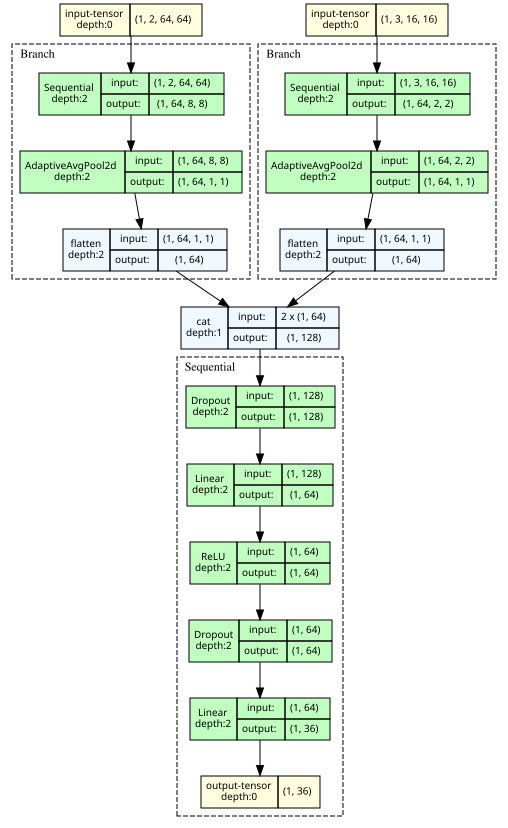

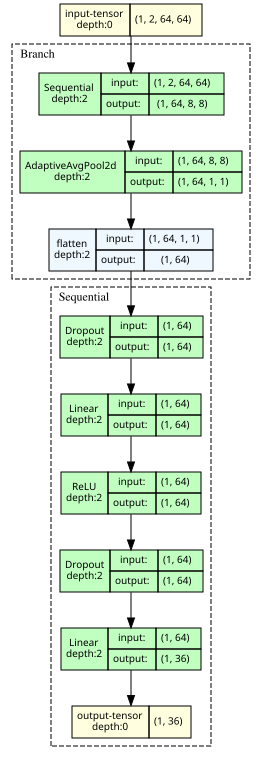

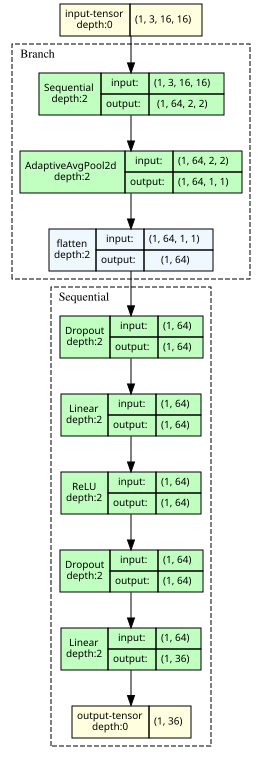

In [12]:
ENC_KW = dict(size=64, mtf_bins=8, lag_samples=(2, 8, 32),
              grid_bins=16, grid_range=(-4.0, 4.0), gaf_scale=None)
n_lags = len(ENC_KW['lag_samples'])
enc = sf.ImageEncoder(**ENC_KW)
n_classes = 36
ts_shape   = (1, 2, enc.size, enc.size)                                   # GAF + MTF
grid_shape = (1, len(enc.lag_samples), enc.grid_bins, enc.grid_bins)      # lag grids

models = {
    'TwoBranch': (sf.build_two_branch(n_classes, n_lags=len(enc.lag_samples)), [ts_shape, grid_shape]),
    'TSOnly':    (sf.build_ts_only(n_classes),                                  ts_shape),
    'GridOnly':  (sf.build_grid_only(n_classes, n_lags=len(enc.lag_samples)),   grid_shape),
}

for name, (model, size) in models.items():
    g = draw_graph(model, input_size=size, device='cpu', graph_name=name,
                   depth=2, expand_nested=True, graph_dir='TB',
                   save_graph=True, filename=name, directory='figures')
    display(g.visual_graph)